# PART 3. Wind reconstruction, evaluation, and turbine production

Load a trained checkpoint and reconstruct before reading withheld target measurements. Compare NN wind with a campaign-fitted speed-only MCP baseline, then apply documented Vestas curves. No training or normalization fitting runs here. Run cells in order with the trained checkpoint available.


In [2]:
"""------------------------ ADJUSTABLE PARAMETERS ------------------------"""
WIND_PATH = "analyses_output_files/wind_pipeline/observations/wind.parquet"     # Cleaned wind
ERA5_PATH = "analyses_output_files/wind_pipeline/observations/era5.parquet"     # Cleaned ERA5
METADATA_PATH = "analyses_output_files/wind_pipeline/metadata/metadata.parquet" # Site metadata
CHECKPOINT_PATH = "analyses_output_files/model/best_context_model.pt"           # Selected trained model
TARGET_SITE = "az15"                    # Reconstruction target
REFERENCE_SITES = ("az06", "az05")      # Ordered model reference slots
CAMPAIGN_START_LOCAL = "2013-01-01"     # First campaign local date
CAMPAIGN_MONTHS = 3                     # Calendar-month duration
START_LOCAL = "2005-01-01"              # First reconstruction date
END_LOCAL = "2019-12-31"                # Last reconstruction date, inclusive
DEVICE = "auto"                         # CUDA if available, otherwise CPU
CONTEXT_MODE = "full"                   # "full" campaign or "trained" count
QUERY_CHUNK_SIZE = 1024                 # Inference query hours per chunk
RANDOM_SEED = 42                        # Separate context-selection RNG
SHEAR_ALPHA = 1 / 7                     # Assumed fixed power-law exponent
TURBINE_HUB_HEIGHTS_M = {               # Assumed heights; documented examples/options
    "V27": 31.5, "V29": 31.0, "V47": 50.0, "V82": 70.0}
DETAILED_TURBINE = "V82"                # Energy and revenue detail plots
PPA_USD_PER_MWH = 50.0                  # ILLUSTRATIVE fixed PPA; not a market quote
LOSS_FRACTION = 0.0                     # Aggregate energy losses, from 0 to below 1
EXCLUDE_CAMPAIGN_FROM_WIND_METRICS = True # Withhold campaign for accuracy scoring
PLOT_START_LOCAL = "2014-01-01"         # Short hourly plot start
PLOT_END_LOCAL = "2014-01-14"           # Short hourly plot end, inclusive
CALM_EVAL_THRESHOLD_MPS = 0.5           # Shared measured/NN calm threshold
ROSE_SECTORS = 16                       # Common direction sectors
ROSE_SPEED_BINS_MPS = (0, 2, 4, 6, 8, 10, 15, 25)   # Final bin extends to infinity
MAX_SCATTER_POINTS = 5000                           # Deterministic plotting sample only
CURVE_FOLDER = "downloaded_datasets/turbine_curves" # Local archived CSVs
OUTPUT_FOLDER = "analyses_output_files/evaluation"  # Saved evaluation tables


## Load the selected trained model

Architecture, feature order, retained metadata, normalization, and preprocessing come from the checkpoint. Saved site roles determine whether the target was used for training or validation; test sites can be reconstructed for final evaluation. Reference order and restrictions are checked by the shared inference helper.


In [3]:
"""------------------------ IMPORTS AND LOAD TRAINED MODEL ------------------------"""
from pathlib import Path
from zoneinfo import ZoneInfo
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from IPython.display import display
import torch
from wind_pipeline import load_checkpoint, assemble_reconstruction_inputs, reconstruct_wind

run_parameters = {k: v for k, v in list(globals().items()) if k.isupper() and not k.startswith('_')}
if not 0 <= LOSS_FRACTION < 1 or PPA_USD_PER_MWH < 0:
    raise ValueError("Require 0 <= losses < 1 and a nonnegative PPA.")
if not np.isfinite(CALM_EVAL_THRESHOLD_MPS) or CALM_EVAL_THRESHOLD_MPS < 0:
    raise ValueError("The evaluation calm threshold must be finite and nonnegative.")
if DETAILED_TURBINE not in TURBINE_HUB_HEIGHTS_M:
    raise ValueError("Select the detailed turbine from TURBINE_HUB_HEIGHTS_M.")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") if DEVICE == "auto" else torch.device(DEVICE)
model, saved, normalization = load_checkpoint(CHECKPOINT_PATH, device)
settings = saved['preprocessing']
local_timezone = settings['local_timezone']
local_tz = ZoneInfo(local_timezone)
roles = saved['site_roles']
target_role = next((role for role, sites in roles.items() if TARGET_SITE in sites), 'unassigned/new site')
if len(REFERENCE_SITES) != settings['n_references'] or len(set(REFERENCE_SITES)) != len(REFERENCE_SITES):
    raise ValueError("References must match the checkpoint's required number of distinct slots.")
if TARGET_SITE in REFERENCE_SITES or not set(REFERENCE_SITES).issubset(roles['development_sites']):
    raise ValueError("References must be saved development sites distinct from the target.")
print("Model:", saved['model_identity'], "| device:", device)
print("Target:", TARGET_SITE, "| saved role:", target_role, "| ordered references:", REFERENCE_SITES)
print("Unseen during model training:", TARGET_SITE not in roles['development_sites'])
print("Saved site roles:", roles)
print("Campaign:", CAMPAIGN_START_LOCAL, "for", CAMPAIGN_MONTHS, "calendar months in", local_timezone)
print("Reconstruction local dates:", START_LOCAL, "through", END_LOCAL)
OUT = Path(OUTPUT_FOLDER)
OUT.mkdir(parents=True, exist_ok=True)
colors = {'Measured benchmark': '#333333', 'NN': '#0072B2', 'MCP': '#D55E00'}
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110})


def time_axis(ax):
    locator = mdates.AutoDateLocator(tz=local_tz)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=local_tz))
    ax.set_xlabel(f"Local interval midpoint ({local_timezone})")


def plot_times(values):
    # UTC-aware Python datetimes preserve instants; time_axis displays local labels.
    return pd.DatetimeIndex(values).tz_convert('UTC').to_pydatetime()


def json_safe(value):
    if isinstance(value, dict):
        return {key: json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


Model: WindContextModel:step=500:validation_loss=0.89783498 | device: cpu
Target: az15 | saved role: test_sites | ordered references: ('az06', 'az05')
Unseen during model training: True
Saved site roles: {'development_sites': ['az06', 'az05', 'az22', 'az26'], 'validation_sites': ['az19'], 'test_sites': ['az15']}
Campaign: 2013-01-01 for 3 calendar months in America/Phoenix
Reconstruction local dates: 2005-01-01 through 2019-12-31


## Reconstruct using campaign data only

Only campaign target observations enter inference. Context selection uses its own seeded generator. Keep every requested hour and the conservative `predictors_complete` flag; False rows are not automatically discarded. This flag describes query inputs, not prediction confidence. Full target observations are read separately in the next cell, after inference is finished.


In [4]:
"""------------------------ RECONSTRUCT TARGET WIND ------------------------"""
arrays, reconstruction_metadata = assemble_reconstruction_inputs(
    WIND_PATH, ERA5_PATH, METADATA_PATH, saved, normalization,
    target=TARGET_SITE, references=REFERENCE_SITES,
    campaign_start_local=CAMPAIGN_START_LOCAL, campaign_months=CAMPAIGN_MONTHS,
    start_local=START_LOCAL, end_local=END_LOCAL,
    context_mode=CONTEXT_MODE, rng=np.random.default_rng(RANDOM_SEED))
reconstructed, reconstruction_metadata = reconstruct_wind(
    model, **arrays, normalization=normalization, device=device,
    query_chunk_size=QUERY_CHUNK_SIZE, reconstruction_metadata=reconstruction_metadata,
    calm_speed_mps=settings['calm_speed_mps'], direction_vector_eps=settings['direction_vector_eps'])
print("Usable campaign hours:", reconstruction_metadata['usable_context_hours'],
      "| NN context hours used:", reconstruction_metadata['context_hours_used'], "| mode:", CONTEXT_MODE)
print("Predictors complete:", f"{reconstructed.predictors_complete.mean():.1%}")
display(reconstructed.head())


Usable campaign hours: 2160 | NN context hours used: 2160 | mode: full
Predictors complete: 99.5%


,time_utc,predicted_speed_mps,predicted_direction_deg,predictors_complete
0,2005-01-01 08:00:00+00:00,1.499940,58.284637,True
1,2005-01-01 09:00:00+00:00,1.195544,47.672621,True
2,2005-01-01 10:00:00+00:00,1.099389,23.315029,True
3,2005-01-01 11:00:00+00:00,1.156784,50.685047,True
4,2005-01-01 12:00:00+00:00,1.242060,54.758431,True


## Align withheld observations and fit MCP

The NN receives measured reference wind, target/reference ERA5, and retained metadata; MCP receives only measured reference speeds. This compares the complete approaches with unequal predictor information, so an improvement cannot be attributed solely to neural-network architecture. No extra baseline is added.

MCP is multiple linear regression with an intercept, fitted to all valid simultaneous campaign speeds using `numpy.linalg.lstsq`. It uses the full campaign even if NN context is subsampled. Target observations outside the campaign are for evaluation only. Campaign membership follows `start < hourly endpoint <= end`; calendar grouping uses local interval midpoints, 30 minutes before endpoints.


In [5]:
"""------------------------ ALIGN OBSERVATIONS AND CAMPAIGN MCP ------------------------"""
aligned = reconstructed.set_index('time_utc').copy()
aligned.index = pd.to_datetime(aligned.index, utc=True)
if aligned.index.has_duplicates or not aligned.index.is_monotonic_increasing:
    raise ValueError("Reconstruction must have unique, ordered hourly UTC endpoints.")
first_utc = aligned.index[0] - pd.Timedelta(hours=1)
last_utc = aligned.index[-1]
observation_sites = [TARGET_SITE, *REFERENCE_SITES]
observations = pd.read_parquet(
    WIND_PATH, columns=['site_id', 'time_utc', 'speed_mps', 'direction_deg', 'speed_valid', 'direction_valid'],
    filters=[('site_id', 'in', observation_sites), ('time_utc', '>', first_utc), ('time_utc', '<=', last_utc)])
if observations.duplicated(['site_id', 'time_utc']).any():
    raise ValueError("Duplicate observation site/timestamp keys.")
valid_speed = observations.speed_valid.astype('boolean').fillna(False) & np.isfinite(observations.speed_mps) & observations.speed_mps.ge(0)
observations['speed_mps'] = observations.speed_mps.where(valid_speed)
valid_direction = (observations.direction_valid.astype('boolean').fillna(False) & valid_speed
                   & observations.speed_mps.gt(0) & np.isfinite(observations.direction_deg))
observations['direction_deg'] = observations.direction_deg.where(valid_direction) % 360
speed_table = observations.pivot(index='time_utc', columns='site_id', values='speed_mps').reindex(aligned.index)
aligned['measured_speed_mps'] = speed_table[TARGET_SITE]
aligned['measured_direction_deg'] = observations.loc[observations.site_id.eq(TARGET_SITE)].set_index('time_utc').direction_deg.reindex(aligned.index)
reference_columns = []
for site in REFERENCE_SITES:
    column = site + '_speed_mps'
    aligned[column] = speed_table[site]
    reference_columns.append(column)
campaign_start = pd.Timestamp(reconstruction_metadata['campaign_start_utc'])
campaign_end = pd.Timestamp(reconstruction_metadata['campaign_end_utc'])
aligned['in_campaign'] = (aligned.index > campaign_start) & (aligned.index <= campaign_end)
fit_rows = aligned.in_campaign & aligned[['measured_speed_mps', *reference_columns]].notna().all(axis=1)
reference_values = aligned[reference_columns].to_numpy(dtype=float)
design = np.column_stack([np.ones(len(aligned)), reference_values])
if fit_rows.sum() < design.shape[1] or np.linalg.matrix_rank(design[fit_rows]) < design.shape[1]:
    raise ValueError("Insufficient independent simultaneous campaign observations for MCP.")
mcp_coefficients = np.linalg.lstsq(design[fit_rows], aligned.loc[fit_rows, 'measured_speed_mps'], rcond=None)[0]
aligned['mcp_speed_mps'] = np.maximum(0., design @ mcp_coefficients)
aligned.loc[~np.isfinite(reference_values).all(axis=1), 'mcp_speed_mps'] = np.nan
local_midpoints = aligned.index.tz_convert(local_timezone) - pd.Timedelta(minutes=30)
speed_columns = {'Measured benchmark': 'measured_speed_mps', 'NN': 'predicted_speed_mps', 'MCP': 'mcp_speed_mps'}
print("MCP fit hours (full valid campaign):", int(fit_rows.sum()),
      "| NN context hours:", reconstruction_metadata['context_hours_used'])


MCP fit hours (full valid campaign): 2160 | NN context hours: 2160


## Wind accuracy and visual comparison

Both roses use the same requested evaluation period (campaign excluded by default), but each independently selects its own valid non-calm directions. Neither rose is filtered by the other method or MCP. Counts partition every requested hour into valid non-calm direction, calm, or missing/undefined direction; their denominator is all requested evaluation hours. Each rose normalizes by its own valid non-calm count.

Speed metrics, distributions, monthly means, and scatter plots use common valid measured/NN/MCP timestamps. Completeness is reported, not used to remove rows.

Both roses use the same physical `CALM_EVAL_THRESHOLD_MPS` (default 0.5 m/s). The separate NN all-valid-target table always excludes campaign hours and retains reference-outage hours when NN and target speeds are valid; coverage reports both requested-hour and valid-target denominators. Direction accuracy also always excludes campaign hours and requires both speeds above the same threshold, without an MCP mask. Circular MAE/RMSE use shortest signed angular errors; circular bias is the circular mean of those errors (NaN when its resultant is numerically zero).


Rose category denominator: all requested evaluation hours; each rose frequency uses its own valid non-calm count.


,method,calm_threshold_mps,requested_evaluation_hours,valid_non_calm_direction_hours,calm_hours,missing_or_undefined_direction_hours,valid_non_calm_fraction,calm_fraction,missing_or_undefined_fraction
0,Measured benchmark,0.5,129312,75458,53640,214,0.583534,0.414811,0.001655
1,NN,0.5,129312,129312,0,0,1.000000,0.000000,0.000000


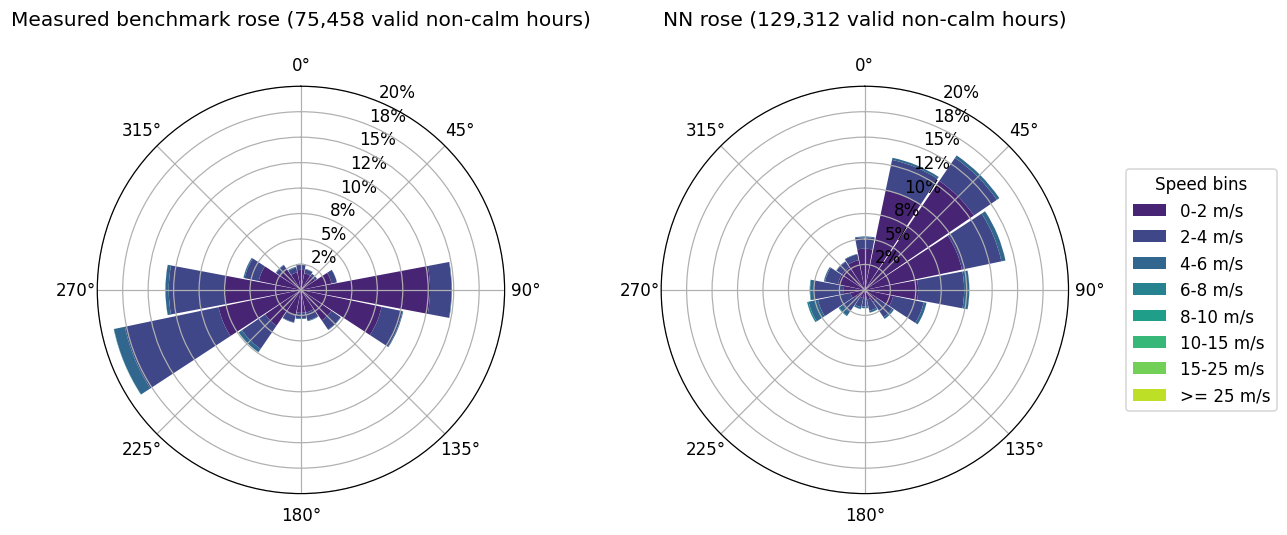

Campaign excluded from head-to-head wind accuracy: True
Predictors complete in requested evaluation hours: 99.5%


,method,scope,bias_mps,mae_mps,rmse_mps,pearson_r,evaluated_hours,requested_evaluation_hours,valid_target_hours,coverage_fraction,valid_target_coverage_fraction
0,NN,head_to_head_common,0.971578,1.052651,1.212565,0.705069,129104,129312,129168,0.998391,0.999505
1,MCP,head_to_head_common,-0.137902,0.556821,0.725973,0.700936,129104,129312,129168,0.998391,0.999505


,method,scope,bias_mps,mae_mps,rmse_mps,pearson_r,evaluated_hours,requested_evaluation_hours,valid_target_hours,coverage_fraction,valid_target_coverage_fraction
0,NN,nn_all_valid_target_hours,0.971535,1.052595,1.212493,0.70515,129168,129312,129168,0.998886,1.0


,method,scope,calm_threshold_mps,circular_mae_deg,circular_rmse_deg,circular_bias_deg,evaluated_hours,requested_out_of_campaign_hours,coverage_fraction
0,NN,out_of_campaign_paired_non_calm,0.5,44.456538,62.262074,-2.470179,75458,129312,0.583534


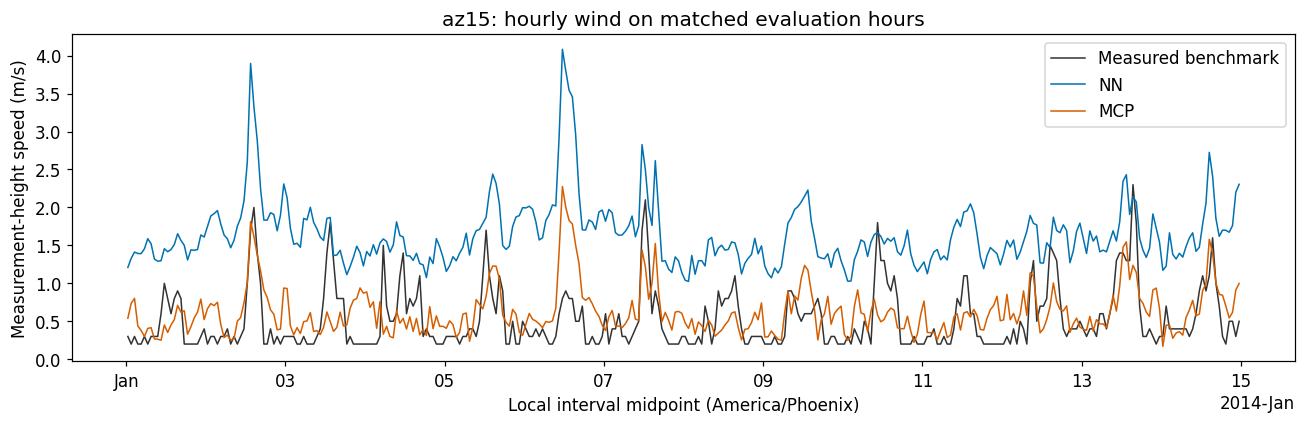

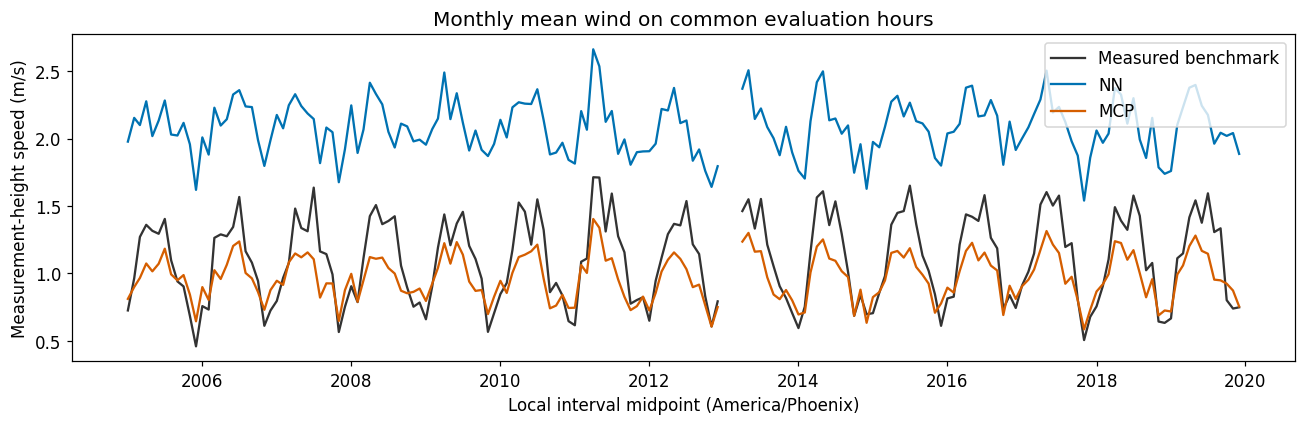

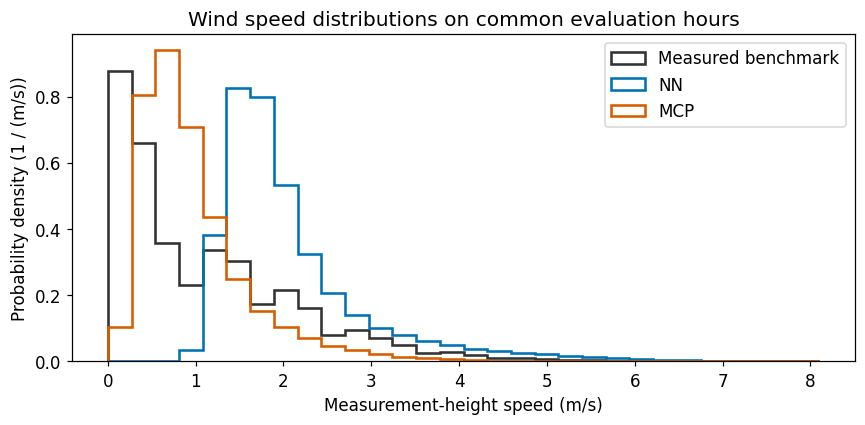

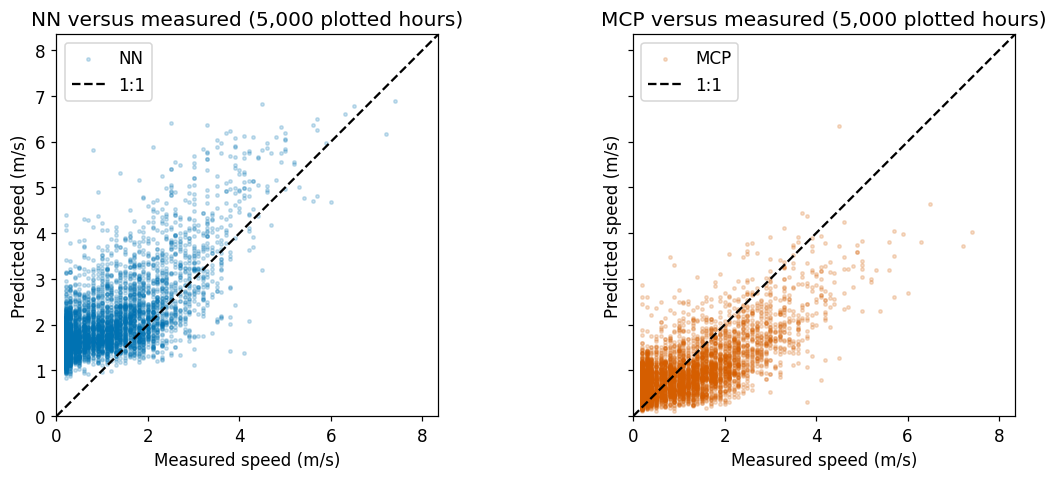

In [6]:
"""------------------------ WIND METRICS AND FIGURES ------------------------"""
evaluation_hours = ~aligned.in_campaign if EXCLUDE_CAMPAIGN_FROM_WIND_METRICS else pd.Series(True, index=aligned.index)

def rose_sample_masks(speed, direction, requested, calm_threshold):
    calm = requested & np.isfinite(speed) & speed.ge(0) & speed.le(calm_threshold)
    valid = (requested & np.isfinite(speed) & speed.gt(calm_threshold)
             & np.isfinite(direction) & direction.ge(0) & direction.lt(360))
    missing = requested & ~(valid | calm)
    return valid, calm, missing


rose_bins = np.array([*ROSE_SPEED_BINS_MPS, np.inf])
sector_width = 360 / ROSE_SECTORS
rose_counts, rose_summary_rows = [], []
for method, speed_col, direction_col, calm_threshold in [
        ('Measured benchmark', 'measured_speed_mps', 'measured_direction_deg', CALM_EVAL_THRESHOLD_MPS),
        ('NN', 'predicted_speed_mps', 'predicted_direction_deg', CALM_EVAL_THRESHOLD_MPS)]:
    valid, calm, missing = rose_sample_masks(aligned[speed_col], aligned[direction_col], evaluation_hours, calm_threshold)
    denominator = int(evaluation_hours.sum())
    valid_count = int(valid.sum())
    rose_summary_rows.append(dict(method=method, calm_threshold_mps=calm_threshold, requested_evaluation_hours=denominator,
        valid_non_calm_direction_hours=valid_count, calm_hours=int(calm.sum()),
        missing_or_undefined_direction_hours=int(missing.sum()),
        valid_non_calm_fraction=valid_count/denominator if denominator else np.nan,
        calm_fraction=calm.sum()/denominator if denominator else np.nan,
        missing_or_undefined_fraction=missing.sum()/denominator if denominator else np.nan))
    shifted_direction = (aligned.loc[valid, direction_col].to_numpy()+sector_width/2) % 360
    counts, _, _ = np.histogram2d(shifted_direction, aligned.loc[valid, speed_col],
                                  bins=[np.linspace(0, 360, ROSE_SECTORS+1), rose_bins])
    rose_counts.append(100*counts/max(1, valid_count))
rose_summary = pd.DataFrame(rose_summary_rows)
print("Rose category denominator: all requested evaluation hours; each rose frequency uses its own valid non-calm count.")
display(rose_summary)
radial_max = max(5., np.ceil(max(c.sum(axis=1).max() for c in rose_counts)/5)*5)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={'projection': 'polar'})
rose_colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(rose_bins)-1))
for ax, counts, summary in zip(axes, rose_counts, rose_summary_rows):
    ax.set_theta_zero_location('N'); ax.set_theta_direction(-1)
    bottom = np.zeros(ROSE_SECTORS)
    for i, color in enumerate(rose_colors):
        label_bin = f'{rose_bins[i]:g}-{rose_bins[i+1]:g} m/s' if np.isfinite(rose_bins[i+1]) else f'>= {rose_bins[i]:g} m/s'
        ax.bar(np.deg2rad(np.arange(ROSE_SECTORS)*sector_width), counts[:, i], width=np.deg2rad(sector_width*0.95), bottom=bottom, color=color, label=label_bin)
        bottom += counts[:, i]
    ax.set_ylim(0, radial_max); ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.set_title(f"{summary['method']} rose ({summary['valid_non_calm_direction_hours']:,} valid non-calm hours)", pad=20)
axes[1].legend(loc='center left', bbox_to_anchor=(1.12, 0.5), title='Speed bins')
fig.tight_layout(); plt.show()

common_speed = evaluation_hours & np.isfinite(aligned[list(speed_columns.values())]).all(axis=1)
comparison = aligned[list(speed_columns.values())].where(common_speed, axis=0)
comparison.columns = list(speed_columns)
comparison.index = local_midpoints
# Keep head-to-head scoring and also score NN when MCP/reference speed is missing.
outside_campaign = ~aligned.in_campaign
nn_target_valid = outside_campaign & np.isfinite(aligned.measured_speed_mps)
nn_all_hours = nn_target_valid & np.isfinite(aligned.predicted_speed_mps)
metric_cases = [('NN', 'head_to_head_common', common_speed, evaluation_hours),
                ('MCP', 'head_to_head_common', common_speed, evaluation_hours),
                ('NN', 'nn_all_valid_target_hours', nn_all_hours, outside_campaign)]
metrics_rows = []
for method, scope, rows, requested in metric_cases:
    measured = aligned.loc[rows, 'measured_speed_mps']
    predicted = aligned.loc[rows, speed_columns[method]]
    error = predicted-measured
    correlation = predicted.corr(measured) if predicted.std() > 0 and measured.std() > 0 else np.nan
    requested_count = int(requested.sum())
    valid_target_count = int((requested & np.isfinite(aligned.measured_speed_mps)).sum())
    metrics_rows.append(dict(method=method, scope=scope, bias_mps=error.mean(), mae_mps=error.abs().mean(),
        rmse_mps=np.sqrt(error.pow(2).mean()), pearson_r=correlation, evaluated_hours=len(error),
        requested_evaluation_hours=requested_count, valid_target_hours=valid_target_count,
        coverage_fraction=len(error)/requested_count if requested_count else np.nan,
        valid_target_coverage_fraction=len(error)/valid_target_count if valid_target_count else np.nan))
all_wind_metrics = pd.DataFrame(metrics_rows)
wind_metrics = all_wind_metrics.loc[all_wind_metrics.scope.eq('head_to_head_common')].reset_index(drop=True)
nn_all_valid_target_hours = all_wind_metrics.loc[all_wind_metrics.scope.eq('nn_all_valid_target_hours')].reset_index(drop=True)

# Paired direction accuracy is independent of MCP and always excludes campaign hours.
measured_direction_rows = rose_sample_masks(aligned.measured_speed_mps, aligned.measured_direction_deg,
                                            outside_campaign, CALM_EVAL_THRESHOLD_MPS)[0]
nn_direction_rows = rose_sample_masks(aligned.predicted_speed_mps, aligned.predicted_direction_deg,
                                     outside_campaign, CALM_EVAL_THRESHOLD_MPS)[0]
direction_rows = measured_direction_rows & nn_direction_rows
angle_error_deg = ((aligned.loc[direction_rows, 'predicted_direction_deg']
                    - aligned.loc[direction_rows, 'measured_direction_deg'] + 180) % 360) - 180
mean_sin = np.sin(np.deg2rad(angle_error_deg)).mean()
mean_cos = np.cos(np.deg2rad(angle_error_deg)).mean()
circular_bias_deg = np.nan
if len(angle_error_deg) and np.hypot(mean_sin, mean_cos) > 1e-12:
    circular_bias_deg = (np.degrees(np.arctan2(mean_sin, mean_cos))+180) % 360-180
direction_metrics = pd.DataFrame([dict(method='NN', scope='out_of_campaign_paired_non_calm',
    calm_threshold_mps=CALM_EVAL_THRESHOLD_MPS, circular_mae_deg=angle_error_deg.abs().mean(),
    circular_rmse_deg=np.sqrt(angle_error_deg.pow(2).mean()), circular_bias_deg=circular_bias_deg,
    evaluated_hours=len(angle_error_deg), requested_out_of_campaign_hours=int(outside_campaign.sum()),
    coverage_fraction=len(angle_error_deg)/outside_campaign.sum() if outside_campaign.any() else np.nan)])
print("Campaign excluded from head-to-head wind accuracy:", EXCLUDE_CAMPAIGN_FROM_WIND_METRICS)
print("Predictors complete in requested evaluation hours:", f"{aligned.loc[evaluation_hours, 'predictors_complete'].mean():.1%}")
display(wind_metrics)
display(nn_all_valid_target_hours)
display(direction_metrics)

if common_speed.any():
    plot_start = pd.Timestamp(PLOT_START_LOCAL).tz_localize(local_timezone)
    plot_end = pd.Timestamp(PLOT_END_LOCAL).tz_localize(local_timezone) + pd.DateOffset(days=1)
    short = comparison.loc[(comparison.index >= plot_start) & (comparison.index < plot_end)]
    if short.dropna(how='all').empty:
        raise ValueError("Choose a short plot period with matched hours in the evaluation period.")
    fig, ax = plt.subplots(figsize=(12, 4))
    for method in speed_columns:
        ax.plot(plot_times(short.index), short[method], label=method, color=colors[method], linewidth=1)
    ax.set(title=f"{TARGET_SITE}: hourly wind on matched evaluation hours", ylabel='Measurement-height speed (m/s)')
    time_axis(ax); ax.legend(); fig.tight_layout(); plt.show()

    monthly_wind = comparison.resample('MS').mean()
    fig, ax = plt.subplots(figsize=(12, 4))
    for method in speed_columns:
        ax.plot(plot_times(monthly_wind.index), monthly_wind[method], label=method, color=colors[method])
    ax.set(title='Monthly mean wind on common evaluation hours', ylabel='Measurement-height speed (m/s)')
    time_axis(ax); ax.legend(); fig.tight_layout(); plt.show()

    bins = np.linspace(0., max(1., np.nanmax(comparison.to_numpy())), 31)
    fig, ax = plt.subplots(figsize=(8, 4))
    for method in speed_columns:
        ax.hist(comparison[method].dropna(), bins=bins, density=True, histtype='step', linewidth=1.7,
                label=method, color=colors[method])
    ax.set(title='Wind speed distributions on common evaluation hours', xlabel='Measurement-height speed (m/s)', ylabel='Probability density (1 / (m/s))')
    ax.legend(); fig.tight_layout(); plt.show()

    scatter_data = comparison.dropna()
    if len(scatter_data) > MAX_SCATTER_POINTS:
        scatter_data = scatter_data.sample(MAX_SCATTER_POINTS, random_state=RANDOM_SEED)
    limit = max(1., float(comparison.max().max())) * 1.03
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
    for ax, method in zip(axes, ('NN', 'MCP')):
        ax.scatter(scatter_data['Measured benchmark'], scatter_data[method], s=5, alpha=0.2, color=colors[method], label=method)
        ax.plot([0, limit], [0, limit], '--', color='black', label='1:1')
        ax.set(title=f'{method} versus measured ({len(scatter_data):,} plotted hours)', xlabel='Measured speed (m/s)',
               ylabel='Predicted speed (m/s)', xlim=(0, limit), ylim=(0, limit), aspect='equal')
        ax.legend()
    fig.tight_layout(); plt.show()
else:
    print("No common measured/NN/MCP speed hours: common-hour plots skipped; NN-only and direction results remain available.")


## Hub-height assumptions and complete local Vestas curves

Use the metadata height (historically assumed 3 m, not independently verified) and the fixed power law $U_{hub}=U_{measured}(h_{hub}/h_{measured})^{\alpha}$ for every method. Height-adjusted measured wind is a benchmark under this assumed shear law, not an independent hub-height measurement. All selected curves use 1.225 kg/m3 without density correction.

The original archive tables cover V27 **3.02-18.19**, V29 **3.61-19.92**, V47 **4.17-17.91**, and V82 **3-20 m/s**. The first three have now been replaced for calculations by complete manufacturer specification tables: [V27, page 6 section 2.6](https://media.mwps.world/static/2021/12/vestas-v27-wind-turbine-general-specifications.pdf), [V29, page 7 section 4.1](https://media.mwps.world/static/2019/01/Vestas-V29-Technical-Specifications.pdf), and [V47 single-generator, PDF page 12 / printed page 6 section 4.1](https://www.ledsjovind.se/ventosum/Vestas_V47.pdf). These tables span **3.5-25**, **3.5-25**, and **4-25 m/s** respectively. V27 and V29 now use the documented 3.5 m/s table boundary instead of the old archive limits. V29/V47 are calculated manufacturer curves; this is a documented replacement of the entire curve, not a splice onto test measurements. V82 retains the [archived manufacturer curve](https://natlabrockies.github.io/turbine-models/VestasV82_1.65MW_82.html).

Numerical table values were checked against source page images. Documented constant-output ranges are represented by their endpoints; no plateau was assumed. Original archive speed ranges are recorded above and in the source manifest for provenance; calculations use only the selected local curves. New local CSVs and `curve_sources.json` record sources, document sections, and PDF checksums; normal runs are offline. Selected hub heights remain assumptions based on documented examples/options.

Interpolate only within tabulated support. Preserve missing wind and any future unsupported operating-range power as NaN; below cut-in and at/above cut-out power is zero. Coverage exclusions are counted below. Conditional comparisons may exclude difficult weather; **equal samples and coverage percentages do not remove selection bias**.


,variant,rated_power_mw,rotor_diameter_m,assumed_hub_height_m,reference_density_kg_m3,cut_in_mps,cut_out_mps,tabulated_min_mps,tabulated_max_mps,full_operating_range_covered,source_url,source_location,curve_file
turbine,,,,,,,,,,,,,
V27,"V27-225 kW, 50 Hz (1994 specification)",0.225,27,31.5,1.225,3.5,25,3.5,25.0,True,https://media.mwps.world/static/2021/12/vestas...,"Printed page 6, section 2.6; item 941129, 13 J...",V27_manufacturer_1.225.csv
V29,V29-225 kW (1996 calculated specification),0.225,29,31.0,1.225,3.5,25,3.5,25.0,True,https://media.mwps.world/static/2019/01/Vestas...,"Printed page 7, section 4.1, 1.225 column; ite...",V29_manufacturer_1.225.csv
V47,V47-660 kW single generator (calculated),0.660,47,50.0,1.225,4.0,25,4.0,25.0,True,https://www.ledsjovind.se/ventosum/Vestas_V47.pdf,"PDF page 12 / printed page 6 of 27, section 4....",V47_manufacturer_1.225.csv
V82,V82-1.65 MW MK II,1.650,82,70.0,1.225,3.5,20,3.0,20.0,True,https://github.com/NatLabRockies/turbine-model...,"Archived manufacturer calculated curve, unchanged",VestasV82_1.65MW_82.csv


Measurement height (historically assumed): 3.0 m | fixed alpha: 0.14285714285714285


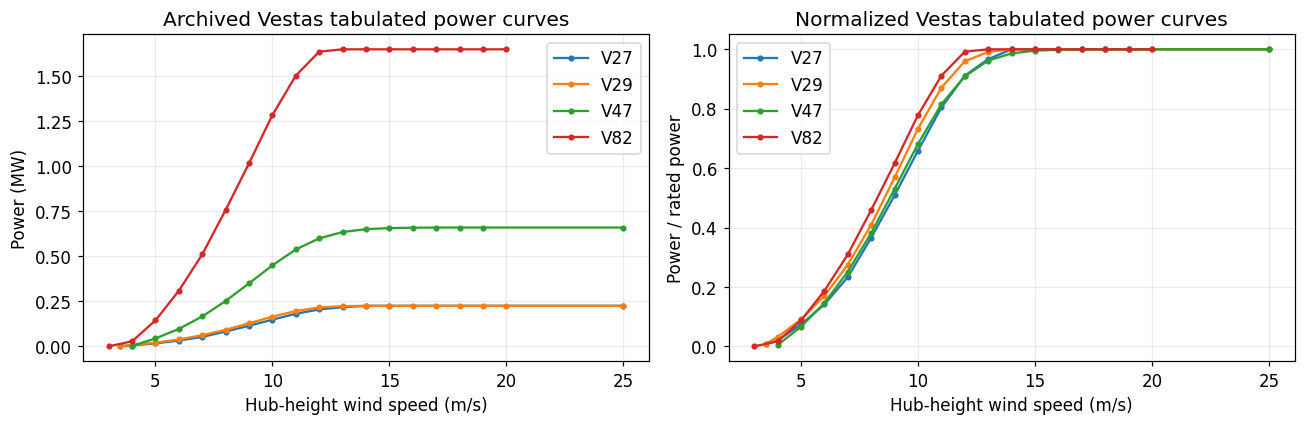

In [7]:
"""------------------------ VESTAS CURVES AND HEIGHT ADJUSTMENT ------------------------"""
archive_commit = 'e9e4ccc6a87f50c0c65d236154a2897e752c47c9'
curve_specs = json.loads((Path(CURVE_FOLDER)/'curve_sources.json').read_text(encoding='utf-8'))
metadata = pd.read_parquet(METADATA_PATH, filters=[('site_id', '==', TARGET_SITE)])
if len(metadata) != 1:
    raise ValueError("Require one target metadata row.")
measurement_height_m = float(metadata.iloc[0].measurement_height_m)
if not np.isfinite(measurement_height_m) or measurement_height_m <= 0:
    raise ValueError("Require a positive measurement height for shear adjustment.")
curves, turbine_rows = {}, []
for turbine, hub_height in TURBINE_HUB_HEIGHTS_M.items():
    spec = curve_specs[turbine]
    cut_in, cut_out = spec['cut_in_mps'], spec['cut_out_mps']
    if hub_height <= 0:
        raise ValueError("Hub heights must be positive.")
    curve = pd.read_csv(Path(CURVE_FOLDER)/spec['file'], usecols=['Wind Speed [m/s]', 'Power [kW]'])
    curve.columns = ['speed_mps', 'power_kw']
    if curve.isna().any().any() or (np.diff(curve.speed_mps) <= 0).any() or (curve.power_kw < 0).any():
        raise ValueError(f"Invalid tabulated curve for {turbine}.")
    curves[turbine] = curve
    turbine_rows.append(dict(turbine=turbine, variant=spec['variant'], rated_power_mw=spec['rated_power_mw'],
        rotor_diameter_m=spec['rotor_diameter_m'], assumed_hub_height_m=hub_height,
        reference_density_kg_m3=spec['reference_density_kg_m3'], cut_in_mps=cut_in, cut_out_mps=cut_out,
        tabulated_min_mps=float(curve.speed_mps.min()), tabulated_max_mps=float(curve.speed_mps.max()),
        full_operating_range_covered=bool(curve.speed_mps.min() <= cut_in and curve.speed_mps.max() >= cut_out),
        source_url=spec['source_url'], source_location=spec['source_location'], curve_file=spec['file']))
turbine_table = pd.DataFrame(turbine_rows).set_index('turbine')
display(turbine_table)
print("Measurement height (historically assumed):", measurement_height_m, "m | fixed alpha:", SHEAR_ALPHA)


def curve_power_mw(speed_mps, curve, cut_in, cut_out):
    speed = np.asarray(speed_mps, dtype=float)
    power = np.interp(speed, curve.speed_mps, curve.power_kw/1000, left=np.nan, right=np.nan)
    power[np.isfinite(speed) & ((speed < cut_in) | (speed >= cut_out))] = 0.
    power[~np.isfinite(speed)] = np.nan
    return power


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for turbine, row in turbine_table.iterrows():
    curve = curves[turbine]
    axes[0].plot(curve.speed_mps, curve.power_kw/1000, '.-', label=turbine)
    axes[1].plot(curve.speed_mps, curve.power_kw/(1000*row.rated_power_mw), '.-', label=turbine)
axes[0].set(title='Archived Vestas tabulated power curves', xlabel='Hub-height wind speed (m/s)', ylabel='Power (MW)')
axes[1].set(title='Normalized Vestas tabulated power curves', xlabel='Hub-height wind speed (m/s)', ylabel='Power / rated power')
for ax in axes: ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()


## Separate energy accuracy from full-period production

Apply curves to each hourly height-adjusted speed, never to mean speed. Each record represents one hour; missing rows never lengthen adjacent intervals. Net MWh equals gross MWh times $(1-loss)$; net capacity factor divides by rated MW times represented hours. Fixed-PPA revenue is net energy times USD/MWh, not profit.

**Primary energy accuracy always excludes the context/MCP campaign**, independently of the optional wind-metrics setting. For each turbine, all three methods use identical out-of-campaign hours with valid simultaneous wind and supported power. The `energy_accuracy` table reports retained fractions and curve-related exclusions; percentage error is NaN if measured energy is zero or unavailable.

**Production covers the full requested period, including campaign hours.** The `production_common_all_turbines` scope uses one intersection across every selected turbine and all three methods, providing equal weather samples for the cross-turbine capacity-factor plot. The `NN_own_available_production` scope separately retains each turbine's available NN hours. These production tables contain no reconstruction-error metric.

Any curve-related exclusion makes energy accuracy and capacity factor conditional on curve-covered weather. Exclusion counts distinguish missing wind from missing curve support, but do not remove selection bias. Monthly/yearly coverage is relative to full local calendar bins; only completely covered calendar years contribute to mean annual energy. Incomplete years are never annualized. The current replacement curves cover the full operating range; the safeguards also handle partial curves.


In [8]:
"""------------------------ ENERGY ACCURACY AND PRODUCTION TOTALS ------------------------"""

def aggregate_production(power_mw, frequency, rated_mw, eligible_wind):
    grouped = power_mw.resample(frequency)
    gross = grouped.sum(min_count=1)
    hours = grouped.count()
    ends = gross.index + (pd.offsets.MonthBegin(1) if frequency == 'MS' else pd.offsets.YearBegin(1))
    expected_hours = (ends-gross.index).total_seconds()/3600
    net = gross*(1-LOSS_FRACTION)
    curve_excluded = eligible_wind.resample(frequency).sum() - hours
    return pd.DataFrame(dict(gross_energy_mwh=gross, net_energy_mwh=net,
        represented_hours=hours, calendar_hours=expected_hours, coverage_fraction=hours/expected_hours,
        curve_related_excluded_hours=curve_excluded,
        net_capacity_factor_curve_covered=net/(rated_mw*hours.replace(0, np.nan)),
        revenue_usd=net*PPA_USD_PER_MWH))


# Raw hourly powers preserve unsupported curve values as NaN.
power_by_turbine, per_turbine_supported = {}, {}
wind_matched = np.isfinite(aligned[list(speed_columns.values())]).all(axis=1).to_numpy()
outside_campaign = ~aligned.in_campaign.to_numpy()
accuracy_wind_matched = wind_matched & outside_campaign
for turbine, row in turbine_table.iterrows():
    height_factor = (row.assumed_hub_height_m/measurement_height_m)**SHEAR_ALPHA
    power = pd.DataFrame(index=local_midpoints)
    for method, column in speed_columns.items():
        power[method] = curve_power_mw(aligned[column].to_numpy()*height_factor,
                                      curves[turbine], row.cut_in_mps, row.cut_out_mps)
    power_by_turbine[turbine] = power
    per_turbine_supported[turbine] = wind_matched & power.notna().all(axis=1).to_numpy()
# One mask for every turbine and method; do not remove campaign from production.
cross_turbine_supported = np.logical_and.reduce(list(per_turbine_supported.values()))
aligned['accuracy_wind_matched'] = accuracy_wind_matched
aligned['cross_turbine_production_supported'] = cross_turbine_supported

accuracy_power, accuracy_rows, curve_coverage_rows = {}, [], []
for turbine, power in power_by_turbine.items():
    supported = per_turbine_supported[turbine] & outside_campaign
    accuracy_power[turbine] = power.where(pd.Series(supported, index=power.index), axis=0)
    aligned[turbine+'_energy_accuracy_supported'] = supported
    requested = int(outside_campaign.sum())
    wind_hours = int(accuracy_wind_matched.sum())
    retained = int(supported.sum())
    excluded = int((accuracy_wind_matched & ~per_turbine_supported[turbine]).sum())
    curve_coverage_rows.append(dict(turbine=turbine, scope='out_of_campaign_energy_accuracy',
        requested_hours=requested, wind_matched_hours=wind_hours, missing_wind_hours=requested-wind_hours,
        curve_related_excluded_hours=excluded, retained_hours=retained,
        retained_wind_fraction=retained/wind_hours if wind_hours else np.nan,
        retained_requested_fraction=retained/requested if requested else np.nan))
    measured_net = accuracy_power[turbine]['Measured benchmark'].sum(min_count=1)*(1-LOSS_FRACTION)
    for method in speed_columns:
        net = accuracy_power[turbine][method].sum(min_count=1)*(1-LOSS_FRACTION)
        error = 100*(net/measured_net-1) if measured_net > 0 else np.nan
        accuracy_rows.append(dict(turbine=turbine, method=method, scope='out_of_campaign_energy_accuracy',
            net_energy_mwh=net, out_of_campaign_energy_error_pct=error,
            net_capacity_factor_curve_covered=net/(turbine_table.loc[turbine, 'rated_power_mw']*retained) if retained else np.nan,
            requested_out_of_campaign_hours=requested, wind_matched_hours=wind_hours,
            represented_hours=retained, curve_related_excluded_hours=excluded,
            retained_wind_fraction=retained/wind_hours if wind_hours else np.nan,
            coverage_fraction=retained/requested if requested else np.nan,
            conditional_on_curve_coverage=bool(excluded)))
energy_accuracy = pd.DataFrame(accuracy_rows)

matched_power, full_nn_power = {}, {}
monthly_tables, yearly_tables, summary_rows = [], [], []
for turbine, power in power_by_turbine.items():
    rated_mw = turbine_table.loc[turbine, 'rated_power_mw']
    matched_power[turbine] = power.where(pd.Series(cross_turbine_supported, index=power.index), axis=0)
    full_nn_power[turbine] = power['NN'].copy()
    common_wind_series = pd.Series(wind_matched, index=power.index)
    series_to_summarize = [('production_common_all_turbines', method, matched_power[turbine][method], common_wind_series)
                           for method in speed_columns]
    nn_wind = pd.Series(np.isfinite(aligned.predicted_speed_mps.to_numpy()), index=power.index)
    series_to_summarize.append(('NN_own_available_production', 'NN', full_nn_power[turbine], nn_wind))
    for scope, method, series, eligible_wind in series_to_summarize:
        monthly = aggregate_production(series, 'MS', rated_mw, eligible_wind)
        yearly = aggregate_production(series, 'YS', rated_mw, eligible_wind)
        monthly_tables.append(monthly.assign(turbine=turbine, scope=scope, method=method).rename_axis('local_period_start').reset_index())
        yearly_tables.append(yearly.assign(turbine=turbine, scope=scope, method=method).rename_axis('local_period_start').reset_index())
        represented_hours = int(series.count())
        wind_hours = int(eligible_wind.sum())
        curve_excluded = wind_hours-represented_hours
        net_mwh = series.sum(min_count=1)*(1-LOSS_FRACTION)
        complete_years = yearly.coverage_fraction.eq(1)
        summary_rows.append(dict(turbine=turbine, scope=scope, method=method,
            period_start_utc=aligned.index[0].isoformat(), period_end_utc=aligned.index[-1].isoformat(),
            net_energy_mwh=net_mwh, mean_complete_year_energy_mwh=yearly.loc[complete_years, 'net_energy_mwh'].mean(),
            complete_calendar_years=int(complete_years.sum()),
            net_capacity_factor_curve_covered=net_mwh/(rated_mw*represented_hours) if represented_hours else np.nan,
            revenue_usd=net_mwh*PPA_USD_PER_MWH, represented_hours=represented_hours,
            requested_hours=len(aligned), coverage_fraction=represented_hours/len(aligned),
            wind_matched_or_available_hours=wind_hours, curve_related_excluded_hours=curve_excluded,
            retained_wind_fraction=represented_hours/wind_hours if wind_hours else np.nan,
            conditional_on_curve_coverage=bool(curve_excluded)))
        if method == 'NN':
            curve_coverage_rows.append(dict(turbine=turbine, scope=scope, requested_hours=len(aligned),
                wind_matched_hours=wind_hours, missing_wind_hours=len(aligned)-wind_hours,
                curve_related_excluded_hours=curve_excluded, retained_hours=represented_hours,
                retained_wind_fraction=represented_hours/wind_hours if wind_hours else np.nan,
                retained_requested_fraction=represented_hours/len(aligned)))
monthly_production = pd.concat(monthly_tables, ignore_index=True)
yearly_production = pd.concat(yearly_tables, ignore_index=True)
energy_summary = pd.DataFrame(summary_rows)
curve_coverage = pd.DataFrame(curve_coverage_rows)
print("Primary energy accuracy excludes campaign; production includes campaign. Curve exclusions may select weather and bias comparisons.")
display(energy_accuracy)
display(curve_coverage)
print("Cross-turbine production mask:", int(cross_turbine_supported.sum()), "common hours across ALL turbines and methods.")
print("Production losses:", f"{LOSS_FRACTION:.1%}", "| illustrative fixed PPA:", PPA_USD_PER_MWH, "USD/MWh")
if not energy_summary.loc[energy_summary.scope.eq('production_common_all_turbines'), 'complete_calendar_years'].gt(0).any():
    print("No complete common-data years: report represented-period totals and capacity factors; no annualization.")


Primary energy accuracy excludes campaign; production includes campaign. Curve exclusions may select weather and bias comparisons.


,turbine,method,scope,net_energy_mwh,out_of_campaign_energy_error_pct,net_capacity_factor_curve_covered,requested_out_of_campaign_hours,wind_matched_hours,represented_hours,curve_related_excluded_hours,retained_wind_fraction,coverage_fraction,conditional_on_curve_coverage
0,V27,Measured benchmark,out_of_campaign_energy_accuracy,176.370974,0.000000,0.006072,129312,129104,129104,0,1.0,0.998391,False
1,V27,NN,out_of_campaign_energy_accuracy,492.923894,179.481303,0.016969,129312,129104,129104,0,1.0,0.998391,False
2,V27,MCP,out_of_campaign_energy_accuracy,41.815720,-76.291042,0.001440,129312,129104,129104,0,1.0,0.998391,False
3,V29,Measured benchmark,out_of_campaign_energy_accuracy,218.223341,0.000000,0.007512,129312,129104,129104,0,1.0,0.998391,False
4,V29,NN,out_of_campaign_energy_accuracy,593.120868,171.795338,0.020418,129312,129104,129104,0,1.0,0.998391,False
5,V29,MCP,out_of_campaign_energy_accuracy,53.428077,-75.516791,0.001839,129312,129104,129104,0,1.0,0.998391,False
6,V47,Measured benchmark,out_of_campaign_energy_accuracy,623.743927,0.000000,0.007320,129312,129104,129104,0,1.0,0.998391,False
7,V47,NN,out_of_campaign_energy_accuracy,1773.737285,184.369468,0.020816,129312,129104,129104,0,1.0,0.998391,False
8,V47,MCP,out_of_campaign_energy_accuracy,139.273778,-77.671321,0.001635,129312,129104,129104,0,1.0,0.998391,False
9,V82,Measured benchmark,out_of_campaign_energy_accuracy,2618.937904,0.000000,0.012294,129312,129104,129104,0,1.0,0.998391,False


,turbine,scope,requested_hours,wind_matched_hours,missing_wind_hours,curve_related_excluded_hours,retained_hours,retained_wind_fraction,retained_requested_fraction
0,V27,out_of_campaign_energy_accuracy,129312,129104,208,0,129104,1.0,0.998391
1,V29,out_of_campaign_energy_accuracy,129312,129104,208,0,129104,1.0,0.998391
2,V47,out_of_campaign_energy_accuracy,129312,129104,208,0,129104,1.0,0.998391
3,V82,out_of_campaign_energy_accuracy,129312,129104,208,0,129104,1.0,0.998391
4,V27,production_common_all_turbines,131472,131264,208,0,131264,1.0,0.998418
5,V27,NN_own_available_production,131472,131472,0,0,131472,1.0,1.000000
6,V29,production_common_all_turbines,131472,131264,208,0,131264,1.0,0.998418
7,V29,NN_own_available_production,131472,131472,0,0,131472,1.0,1.000000
8,V47,production_common_all_turbines,131472,131264,208,0,131264,1.0,0.998418
9,V47,NN_own_available_production,131472,131472,0,0,131472,1.0,1.000000


Cross-turbine production mask: 131264 common hours across ALL turbines and methods.
Production losses: 0.0% | illustrative fixed PPA: 50.0 USD/MWh


## Scope-aware comparisons and saved results

`energy_accuracy.csv` is the primary campaign-free reconstruction result: measured, NN, and MCP totals use identical timestamps for each turbine. `turbine_energy_revenue_summary.csv`, monthly, and yearly tables are full-requested-period **production**, including campaign. Their `production_common_all_turbines` rows share identical timestamps across every selected turbine and method. NN-own available production remains separate. `curve_coverage.csv` reports curve exclusions after wind availability filtering; `aligned_comparison.csv` retains the per-hour masks for audit.

The capacity-factor figure uses the full-period cross-turbine intersection and is conditional on curve-covered hours. Equal samples do not eliminate any weather-selection bias caused by incomplete curves. Monthly plots show calendar coverage. Cumulative revenue sums known hours only, breaks at missing rows, and marks gaps; resuming after gaps never estimates missing revenue.

The historical 3 m assumption, fixed shear exponent, reference density, hourly approximation, selected losses, and illustrative fixed PPA remain. Revenue is sales revenue, not profit; cost models are excluded.

`wind_metrics.csv` keeps the common-hour head-to-head results; `nn_all_valid_target_hours.csv` separately assesses NN on available target hours, including reference outages. `direction_metrics.csv` reports paired out-of-campaign circular errors. Plotting converts aware times to UTC Python datetimes while displaying America/Phoenix labels. JSON metadata recursively writes nonfinite numeric values as null.


,turbine,scope,method,period_start_utc,period_end_utc,net_energy_mwh,mean_complete_year_energy_mwh,complete_calendar_years,net_capacity_factor_curve_covered,revenue_usd,represented_hours,requested_hours,coverage_fraction,wind_matched_or_available_hours,curve_related_excluded_hours,retained_wind_fraction,conditional_on_curve_coverage
0,V27,production_common_all_turbines,Measured benchmark,2005-01-01T08:00:00+00:00,2020-01-01T07:00:00+00:00,177.971178,12.005655,10,0.006026,8898.558889,131264,131472,0.998418,131264,0,1.0,False
1,V27,production_common_all_turbines,NN,2005-01-01T08:00:00+00:00,2020-01-01T07:00:00+00:00,498.702778,32.670037,10,0.016885,24935.138920,131264,131472,0.998418,131264,0,1.0,False
2,V27,production_common_all_turbines,MCP,2005-01-01T08:00:00+00:00,2020-01-01T07:00:00+00:00,42.434545,2.743770,10,0.001437,2121.727230,131264,131472,0.998418,131264,0,1.0,False
3,V27,NN_own_available_production,NN,2005-01-01T08:00:00+00:00,2020-01-01T07:00:00+00:00,499.759255,33.317284,15,0.016894,24987.962735,131472,131472,1.000000,131472,0,1.0,False
4,V29,production_common_all_turbines,Measured benchmark,2005-01-01T08:00:00+00:00,2020-01-01T07:00:00+00:00,220.218959,14.873407,10,0.007456,11010.947956,131264,131472,0.998418,131264,0,1.0,False
5,V29,production_common_all_turbines,NN,2005-01-01T08:00:00+00:00,2020-01-01T07:00:00+00:00,600.114511,39.335815,10,0.020319,30005.725528,131264,131472,0.998418,131264,0,1.0,False
6,V29,production_common_all_turbines,MCP,2005-01-01T08:00:00+00:00,2020-01-01T07:00:00+00:00,54.208268,3.519418,10,0.001835,2710.413395,131264,131472,0.998418,131264,0,1.0,False
7,V29,NN_own_available_production,NN,2005-01-01T08:00:00+00:00,2020-01-01T07:00:00+00:00,601.362092,40.090806,15,0.020329,30068.104599,131472,131472,1.000000,131472,0,1.0,False
8,V47,production_common_all_turbines,Measured benchmark,2005-01-01T08:00:00+00:00,2020-01-01T07:00:00+00:00,629.388414,42.444491,10,0.007265,31469.420690,131264,131472,0.998418,131264,0,1.0,False
9,V47,production_common_all_turbines,NN,2005-01-01T08:00:00+00:00,2020-01-01T07:00:00+00:00,1794.409815,117.518114,10,0.020712,89720.490730,131264,131472,0.998418,131264,0,1.0,False


,local_period_start,scope,method,net_energy_mwh,represented_hours,calendar_hours,coverage_fraction,revenue_usd
180,2005-01-01 00:00:00-07:00,production_common_all_turbines,Measured benchmark,142.840005,8760,8760.0,1.000000,7142.000261
181,2006-01-01 00:00:00-07:00,production_common_all_turbines,Measured benchmark,152.860822,8736,8760.0,0.997260,7643.041077
182,2007-01-01 00:00:00-07:00,production_common_all_turbines,Measured benchmark,188.937720,8760,8760.0,1.000000,9446.885997
183,2008-01-01 00:00:00-07:00,production_common_all_turbines,Measured benchmark,175.924704,8768,8784.0,0.998179,8796.235206
184,2009-01-01 00:00:00-07:00,production_common_all_turbines,Measured benchmark,170.285290,8688,8760.0,0.991781,8514.264480
185,2010-01-01 00:00:00-07:00,production_common_all_turbines,Measured benchmark,189.570105,8736,8760.0,0.997260,9478.505264
186,2011-01-01 00:00:00-07:00,production_common_all_turbines,Measured benchmark,231.848539,8760,8760.0,1.000000,11592.426969
187,2012-01-01 00:00:00-07:00,production_common_all_turbines,Measured benchmark,153.410022,8784,8784.0,1.000000,7670.501111
188,2013-01-01 00:00:00-07:00,production_common_all_turbines,Measured benchmark,153.160090,8760,8760.0,1.000000,7658.004511
189,2014-01-01 00:00:00-07:00,production_common_all_turbines,Measured benchmark,159.695486,8760,8760.0,1.000000,7984.774301


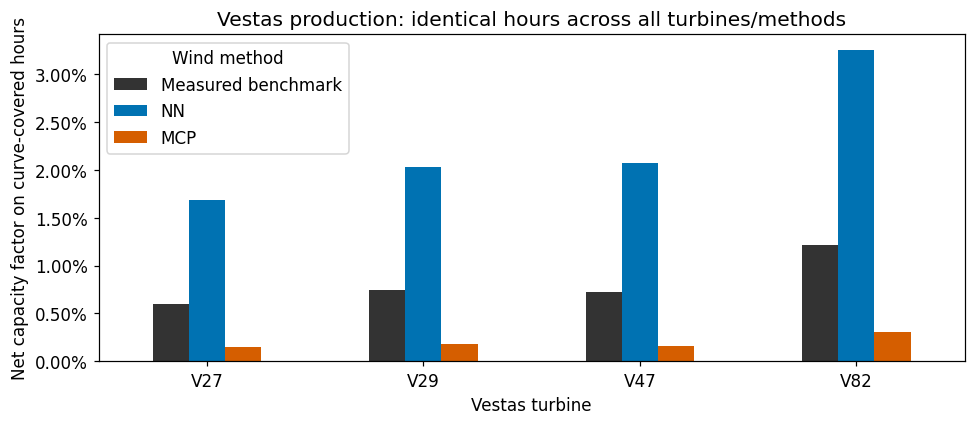

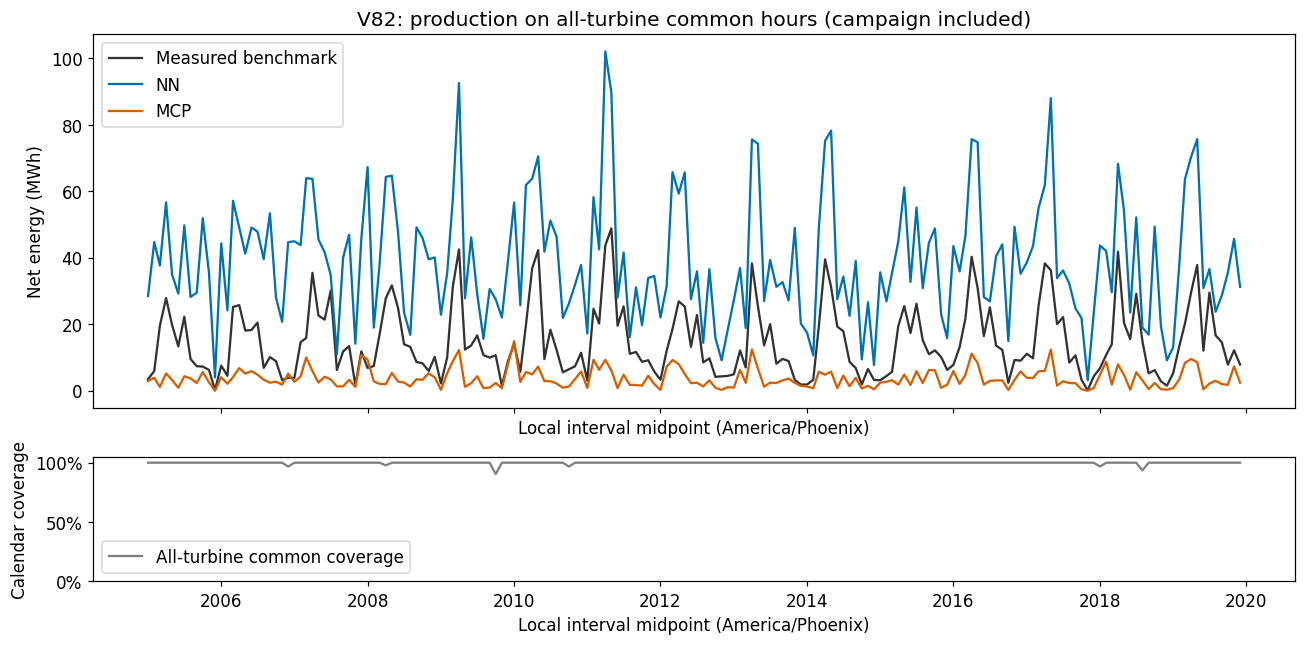

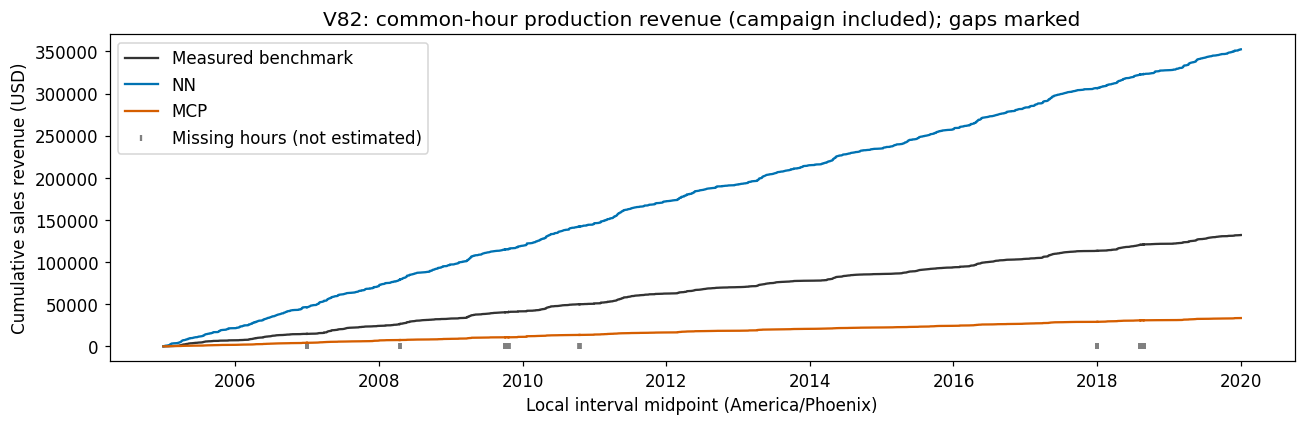

Saved evaluation tables, wind series, sources, and run metadata to C:\Users\ballen47.ASURITE\Documents\VS Code\SCHOOL\Wind-Energy_Machine-Learning_Final-Project\analyses_output_files\evaluation


In [9]:
"""------------------------ FINAL TABLES, FIGURES, AND SAVE ------------------------"""
display(energy_summary)
display(yearly_production.query("turbine == @DETAILED_TURBINE")[
    ['local_period_start', 'scope', 'method', 'net_energy_mwh', 'represented_hours', 'calendar_hours', 'coverage_fraction', 'revenue_usd']])
cf_table = energy_summary.query("scope == 'production_common_all_turbines'").pivot(index='turbine', columns='method', values='net_capacity_factor_curve_covered')
fig, ax = plt.subplots(figsize=(9, 4))
cf_table[list(speed_columns)].plot.bar(ax=ax, color=[colors[m] for m in speed_columns], rot=0)
ax.set(title='Vestas production: identical hours across all turbines/methods', xlabel='Vestas turbine', ylabel='Net capacity factor on curve-covered hours')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1)); ax.legend(title='Wind method'); fig.tight_layout(); plt.show()

monthly_detail = monthly_production.query("turbine == @DETAILED_TURBINE and scope == 'production_common_all_turbines'")
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
for method in speed_columns:
    values = monthly_detail.loc[monthly_detail.method.eq(method)]
    axes[0].plot(plot_times(values.local_period_start), values.net_energy_mwh, label=method, color=colors[method])
coverage = monthly_detail.loc[monthly_detail.method.eq('Measured benchmark')]
axes[1].plot(plot_times(coverage.local_period_start), coverage.coverage_fraction, color='gray', label='All-turbine common coverage')
axes[0].set(title=f'{DETAILED_TURBINE}: production on all-turbine common hours (campaign included)', ylabel='Net energy (MWh)')
axes[1].set(ylabel='Calendar coverage', ylim=(0, 1.05)); axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
for ax in axes: time_axis(ax); ax.legend()
fig.tight_layout(); plt.show()

power_detail = matched_power[DETAILED_TURBINE]
fig, ax = plt.subplots(figsize=(12, 4))
for method in speed_columns:
    cumulative_revenue = (power_detail[method]*(1-LOSS_FRACTION)*PPA_USD_PER_MWH).cumsum(skipna=True)
    ax.plot(plot_times(cumulative_revenue.index), cumulative_revenue, label=method, color=colors[method])
gaps = power_detail.isna().any(axis=1)
ax.scatter(plot_times(power_detail.index[gaps]), np.zeros(int(gaps.sum())), marker='|', s=12, color='gray', label='Missing hours (not estimated)')
ax.set(title=f'{DETAILED_TURBINE}: common-hour production revenue (campaign included); gaps marked', ylabel='Cumulative sales revenue (USD)')
time_axis(ax); ax.legend(); fig.tight_layout(); plt.show()

reconstructed.to_csv(OUT/'reconstructed_wind.csv', index=False)
aligned.rename_axis('time_utc').reset_index().to_csv(OUT/'aligned_comparison.csv', index=False)
wind_metrics.to_csv(OUT/'wind_metrics.csv', index=False)
nn_all_valid_target_hours.to_csv(OUT/'nn_all_valid_target_hours.csv', index=False)
direction_metrics.to_csv(OUT/'direction_metrics.csv', index=False)
rose_summary.to_csv(OUT/'wind_rose_counts.csv', index=False)
energy_accuracy.to_csv(OUT/'energy_accuracy.csv', index=False)
curve_coverage.to_csv(OUT/'curve_coverage.csv', index=False)
energy_summary.to_csv(OUT/'turbine_energy_revenue_summary.csv', index=False)
monthly_production.to_csv(OUT/'monthly_production.csv', index=False)
yearly_production.to_csv(OUT/'yearly_production.csv', index=False)
turbine_table.to_csv(OUT/'turbine_sources.csv')
run_record = dict(parameters=run_parameters, reconstruction_metadata=reconstruction_metadata,
                  saved_site_roles=roles, target_saved_role=target_role, model_identity=saved['model_identity'],
                  mcp_fit_hours=int(fit_rows.sum()), mcp_coefficients=mcp_coefficients.tolist(),
                  reference_slot_order=list(REFERENCE_SITES), measurement_height_m=measurement_height_m,
                  reference_density_kg_m3=1.225, turbine_archive_commit=archive_commit,
                  curve_sources=curve_specs,
                  energy_accuracy_scope='Always out of campaign, per-turbine identical hours across methods',
                  cross_turbine_scope='Full period including campaign; identical hours across all turbines and methods',
                  curve_tail_policy='Unsupported operating-range power remains NaN; exclusions may bias weather samples; zero outside operating limits')
(OUT/'run_parameters_and_metadata.json').write_text(json.dumps(json_safe(run_record), indent=2, default=str, allow_nan=False), encoding='utf-8')
print("Saved evaluation tables, wind series, sources, and run metadata to", OUT.resolve())
